# EXP003 — Controlled Image Preprocessing

## Stage 1: Visual Preprocessing Study

This notebook begins **EXP003** by visually studying controlled image preprocessing operations before running OCR.

### Research Question

> **RQ2: Does controlled image preprocessing improve pretrained TrOCR recognition accuracy on IAM handwriting?**

At this stage, we do **not** run TrOCR. The goal is to understand how each transformation changes the handwriting image and whether it may preserve or damage useful stroke information.

### Conditions explored

- Original
- Grayscale
- Otsu thresholding
- CLAHE contrast enhancement
- Denoising

Deskewing will be added later after a reliable skew-angle estimation method is defined and visually validated.


## 1. Project Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

cwd = Path.cwd().resolve()

if (cwd / "src").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Open this notebook from "
        "trocr_beginner_project/ or trocr_beginner_project/notebooks/."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    grayscale,
    threshold_otsu,
    enhance_contrast,
    denoise,
)

print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)


Project root: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project
Python: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/.venv/bin/python


## 2. Load IAM Validation Manifest

EXP003 uses validation data while preprocessing methods are being developed. The held-out IAM test set should not be repeatedly used to choose preprocessing parameters.

In [2]:
VALIDATION_CSV = (
    PROJECT_ROOT
    / "data"
    / "iam"
    / "validation.csv"
)

if not VALIDATION_CSV.exists():
    raise FileNotFoundError(
        f"Validation CSV not found:\n{VALIDATION_CSV}"
    )

validation_df = pd.read_csv(VALIDATION_CSV)

required = {"id", "image", "text"}
missing = required - set(validation_df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

print("Validation CSV:", VALIDATION_CSV)
print("Validation samples:", len(validation_df))
print("Columns:", validation_df.columns.tolist())

validation_df.head()


Validation CSV: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/data/iam/validation.csv
Validation samples: 1539
Columns: ['id', 'image', 'text']


,id,image,text
0,c04-110-01,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,"assuredness "" Bella Bella Marie "" ( Parlophone..."
1,c04-110-03,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,"CHRIS CHARLES , 39 , who lives in Stockton-on-..."
2,c04-116-00,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,He is also a director of a couple of garages ....
3,c04-116-01,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,"writer . He writes with Tolchard Evans , compo..."
4,c04-116-02,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,"Tolch , as he is known in Tin Pan Alley , like..."


## 3. Verify Validation Image Paths

In [3]:
missing_images = [
    p for p in validation_df["image"]
    if not Path(p).exists()
]

if missing_images:
    print(f"WARNING: {len(missing_images)} image paths are missing.")
    print("First missing path:", missing_images[0])
else:
    print(f"All {len(validation_df)} validation image paths verified successfully.")


All 1539 validation image paths verified successfully.


## 4. Create Reproducible DEV100 Subset

Use a random validation subset rather than the first 100 rows. `random_state=42` makes the selection reproducible.

In [4]:
DEV_N = 100
RANDOM_SEED = 42

if len(validation_df) < DEV_N:
    raise ValueError(
        f"Validation set has only {len(validation_df)} samples; "
        f"cannot select DEV_N={DEV_N}."
    )

dev_df = (
    validation_df
    .sample(n=DEV_N, random_state=RANDOM_SEED)
    .reset_index(drop=True)
)

print("DEV samples:", len(dev_df))
print("Random seed:", RANDOM_SEED)

dev_df.head()


DEV samples: 100
Random seed: 42


,id,image,text
0,r03-053-00,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,"His voice was like his black and pin-stripe ,"
1,f04-093-08,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,"a man "" very close in conversation and"
2,d04-121-05,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,questions is seeking the opinion of the one wh...
3,e06-015-02,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,though somewhat dim picture .
4,f07-092b-02,/Users/aloyson/Documents/Thesis/ocr-thesis-han...,turbot and to have been much more interested i...


## 5. Save DEV100 Selection

In [5]:
EXP003_OUTPUT_DIR = PROJECT_ROOT / "outputs" / "exp003"
EXP003_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEV_SAMPLE_PATH = EXP003_OUTPUT_DIR / "validation_dev100.csv"

dev_df.to_csv(DEV_SAMPLE_PATH, index=False)

print("Saved reproducible DEV100 selection to:")
print(DEV_SAMPLE_PATH)


Saved reproducible DEV100 selection to:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/validation_dev100.csv


## 6. Visualize One Sample Before Preprocessing

Start by inspecting the original IAM line and its ground-truth transcription.

DEV row: 0
IAM ID: r03-053-00
Ground truth: His voice was like his black and pin-stripe ,
Image size: (1738, 131)
Image mode: RGB
Path: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/data/iam/lines/r03/r03-053/r03-053-00.png


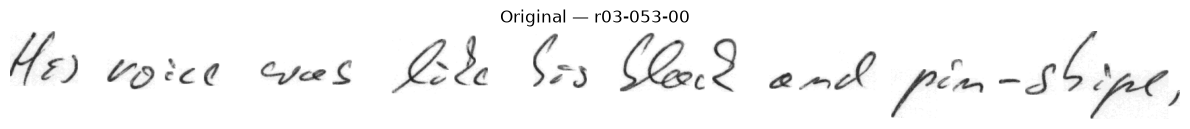

In [6]:
SAMPLE_INDEX = 0

row = dev_df.iloc[SAMPLE_INDEX]
image_path = Path(row["image"])
image = Image.open(image_path).convert("RGB")

print("DEV row:", SAMPLE_INDEX)
print("IAM ID:", row["id"])
print("Ground truth:", row["text"])
print("Image size:", image.size)
print("Image mode:", image.mode)
print("Path:", image_path)

plt.figure(figsize=(12, 3))
plt.imshow(image)
plt.title(f"Original — {row['id']}")
plt.axis("off")
plt.tight_layout()
plt.show()


## 7. Apply Controlled Preprocessing Operations

Each operation is applied independently to the **same original image**. We are not chaining transformations at this stage.

In [7]:
gray = grayscale(image)
binary = threshold_otsu(image)
contrast = enhance_contrast(image)
cleaned = denoise(image)

print("Original mode:", image.mode)
print("Grayscale mode:", gray.mode)
print("Otsu mode:", binary.mode)
print("CLAHE mode:", contrast.mode)
print("Denoised mode:", cleaned.mode)


Original mode: RGB
Grayscale mode: L
Otsu mode: L
CLAHE mode: L
Denoised mode: L


## 8. Compare Original vs Preprocessed Images

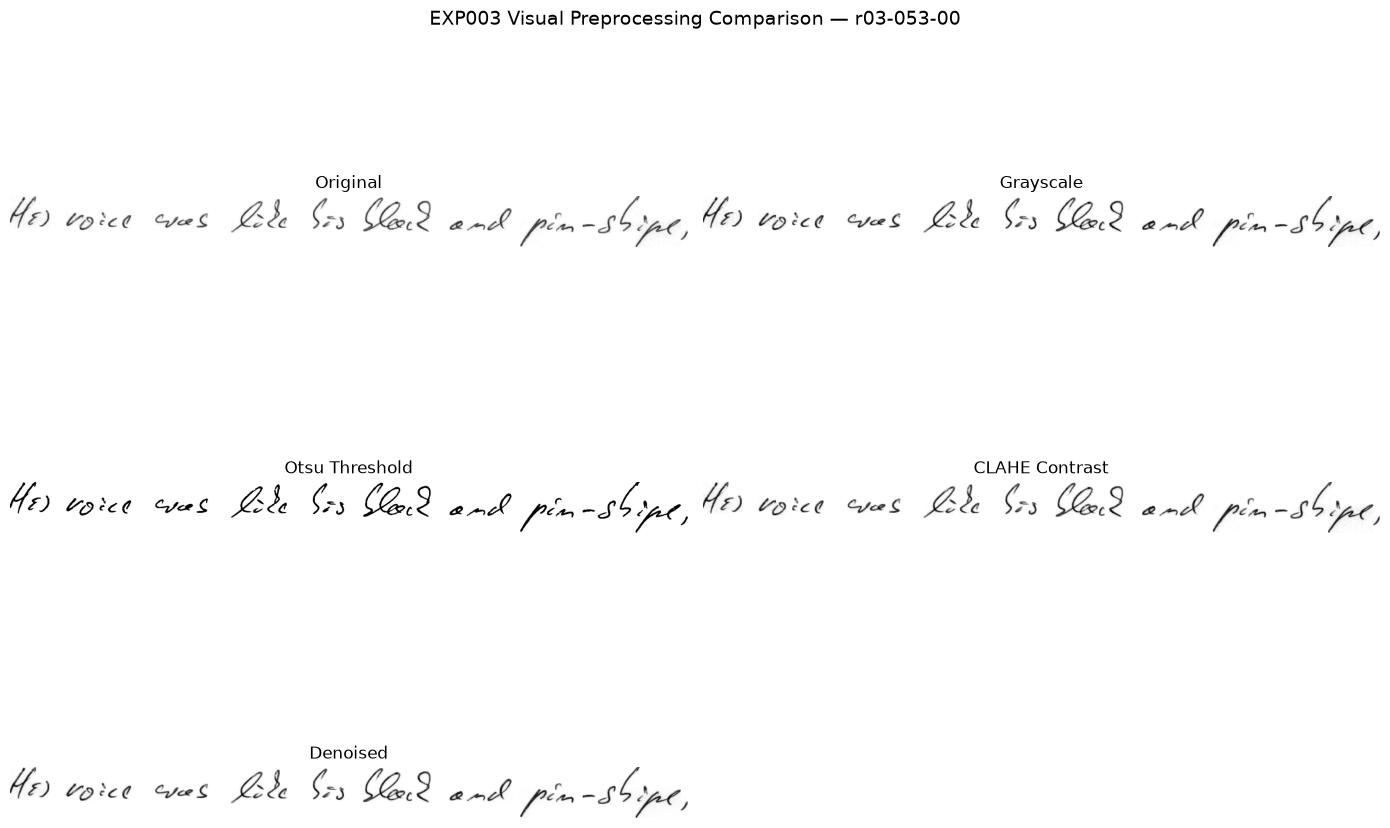

In [8]:
images = [
    ("Original", image),
    ("Grayscale", gray),
    ("Otsu Threshold", binary),
    ("CLAHE Contrast", contrast),
    ("Denoised", cleaned),
]

plt.figure(figsize=(14, 10))

for i, (title, img) in enumerate(images, start=1):
    plt.subplot(3, 2, i)

    if img.mode == "L":
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(img)

    plt.title(title)
    plt.axis("off")

plt.suptitle(
    f"EXP003 Visual Preprocessing Comparison — {row['id']}",
    fontsize=14
)
plt.tight_layout()
plt.show()


## 9. Inspect Multiple DEV100 Samples

Use this helper to inspect several IAM lines without changing the experimental sample selection.

In [9]:
def compare_preprocessing(sample_index: int):
    if sample_index < 0 or sample_index >= len(dev_df):
        raise IndexError(
            f"sample_index must be between 0 and {len(dev_df) - 1}"
        )

    sample = dev_df.iloc[sample_index]
    original = Image.open(sample["image"]).convert("RGB")

    variants = [
        ("Original", original),
        ("Grayscale", grayscale(original)),
        ("Otsu Threshold", threshold_otsu(original)),
        ("CLAHE Contrast", enhance_contrast(original)),
        ("Denoised", denoise(original)),
    ]

    print("DEV row:", sample_index)
    print("IAM ID:", sample["id"])
    print("Ground truth:", sample["text"])
    print("Original size:", original.size)

    plt.figure(figsize=(14, 10))

    for i, (title, variant) in enumerate(variants, start=1):
        plt.subplot(3, 2, i)

        if variant.mode == "L":
            plt.imshow(variant, cmap="gray")
        else:
            plt.imshow(variant)

        plt.title(title)
        plt.axis("off")

    plt.suptitle(
        f"EXP003 Visual Comparison — {sample['id']}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()


DEV row: 75
IAM ID: f07-021b-02
Ground truth: Britons , I believe , used to make water hot
Original size: (1929, 128)


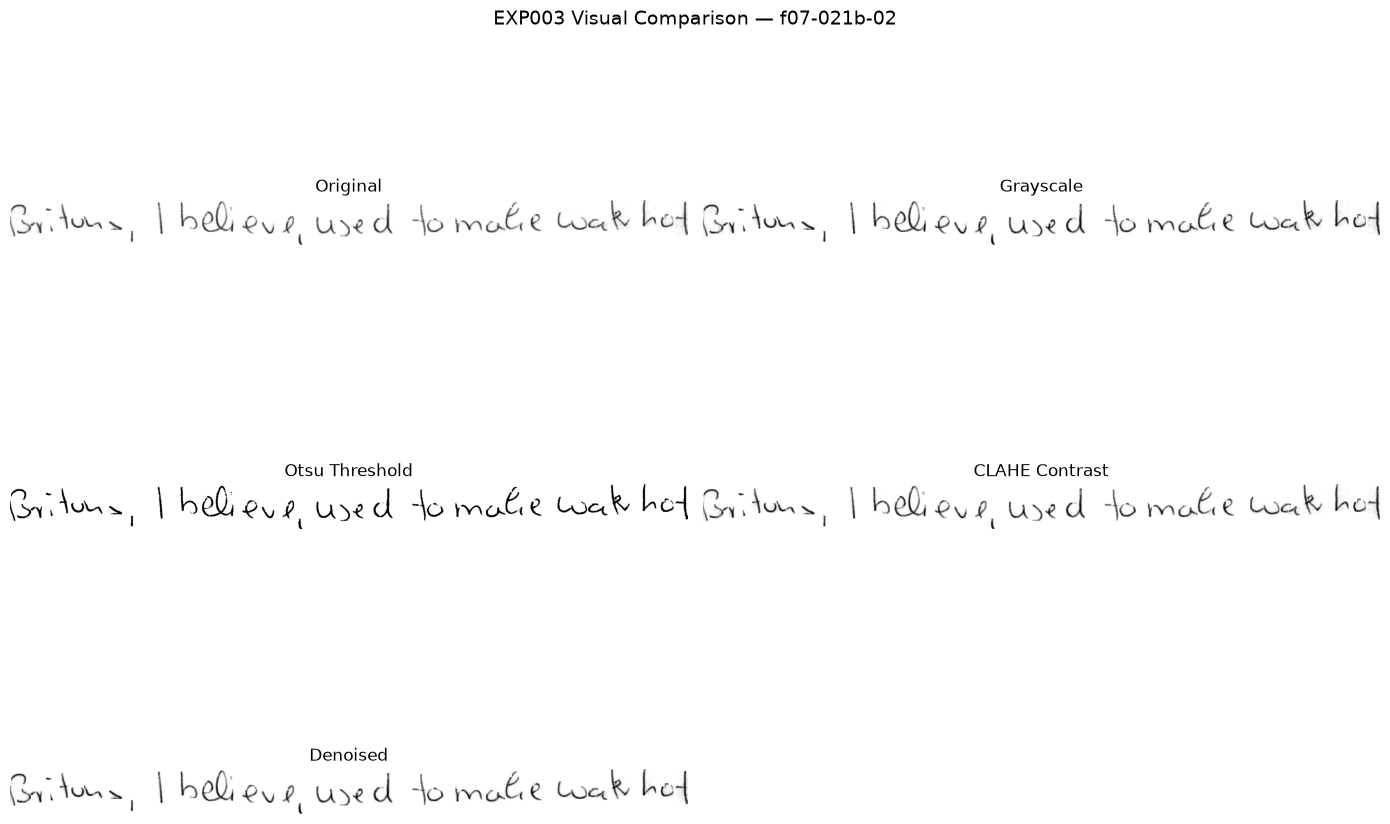

In [19]:
# Try several samples. Change these indices as you review DEV100.
compare_preprocessing(75)


## 10. Suggested Visual Review

Inspect approximately **5–10 different DEV100 images** before running OCR.

For each image, ask:

### Grayscale
- Does it visibly change anything meaningful?
- Is IAM already effectively grayscale?

### Otsu Thresholding
- Are thin handwriting strokes preserved?
- Are strokes broken or merged?
- Is background noise removed?

### CLAHE Contrast Enhancement
- Does faint handwriting become clearer?
- Does background noise become stronger too?

### Denoising
- Are scan artifacts reduced?
- Are fine handwriting details accidentally removed?

### General
- Which transformations preserve the original handwriting most faithfully?
- Which transformations appear risky?
- Do effects differ between clean and degraded samples?

Do **not** conclude that a visually cleaner image necessarily produces better OCR. That must be measured in the next stage.

## 11. Visual Preprocessing Observations

I visually inspected 10 samples from the reproducible DEV100 IAM validation subset.

The selected samples contained different handwriting styles, including thin and faint cursive writing, darker handwriting, separated characters, and connected cursive text.

The goal of this visual inspection was not to select the best preprocessing method, but to verify that each transformation behaved as expected before performing quantitative TrOCR evaluation.

### Original

The original IAM line images were generally clean and readable.

Most samples had:

- a mostly white background,
- limited visible noise,
- clear separation between handwriting and background,
- and sufficient contrast for the handwriting to remain visible.

However, handwriting characteristics varied considerably between samples. Some samples contained dark and clearly separated characters, while others contained thin, faint, or highly cursive strokes.

This variation appears to be related more to handwriting style and stroke intensity than to severe image degradation.

---

### Grayscale

Grayscale conversion produced almost no visible change compared with the original images.

Across the inspected samples:

- handwriting structure was preserved,
- stroke thickness remained similar,
- background appearance remained nearly unchanged,
- and no obvious new information was introduced.

This is expected because the IAM line images already contain very little meaningful color information.

Based on visual inspection alone, explicit grayscale conversion does not appear to provide a substantial visual advantage over the original images.

However, this still needs to be verified quantitatively using TrOCR.

---

### Otsu Thresholding

Otsu thresholding produced the largest visual change among the tested preprocessing methods.

The transformation converted the images into a much stronger foreground/background representation:

- handwriting strokes became darker,
- the background became almost completely white,
- faint gray variations in the background were removed,
- and character boundaries often appeared sharper.

For several samples, particularly those containing faint handwriting, the text became visually more prominent.

However, thresholding also changes the original stroke intensity information.

Thin or lightly written strokes may potentially be altered or lost, while some strokes may appear thicker than in the original image.

Therefore, although Otsu thresholding often produces a visually cleaner image, it cannot be assumed that this will improve TrOCR recognition.

---

### CLAHE Contrast Enhancement

CLAHE increased local contrast while preserving the grayscale structure of the handwriting.

In several samples, faint handwriting became slightly darker and easier to distinguish.

However, CLAHE also made local background variations more visible.

Some images showed noticeable gray rectangular or patch-like regions around parts of the handwriting after contrast enhancement.

Therefore, CLAHE appears capable of strengthening faint strokes, but it may also amplify background artifacts or local intensity variations that were less visible in the original image.

Its effect appears more variable than Otsu thresholding.

---

### Denoising

Denoising produced relatively subtle visual changes.

The overall handwriting structure was preserved across the inspected samples.

Compared with the original images:

- small intensity variations appeared slightly smoother,
- handwriting remained readable,
- and there was no obvious severe loss of stroke information.

However, because most IAM samples were already relatively clean, the denoising transformation did not produce a major visible improvement.

For faint handwriting, excessive smoothing could potentially reduce useful stroke detail, although no severe degradation was obvious in the inspected examples.

---

## Comparison Across Methods

The visual inspection suggests the following general behavior:

| Method | Visual Observation |
|---|---|
| Original | Generally clean and readable baseline |
| Grayscale | Almost identical to original |
| Otsu Thresholding | Strongest change; darker strokes and clean white background |
| CLAHE | Strengthens local contrast but may amplify background artifacts |
| Denoising | Subtle smoothing; generally preserves handwriting |

The effect of preprocessing also depended on handwriting style.

Dark and clearly written samples changed relatively little in terms of readability, while faint or thin handwriting showed more visible differences after thresholding and contrast enhancement.

---

## Initial Interpretation

No preprocessing method was consistently visually superior across all 10 inspected samples.

Otsu thresholding produced the clearest visual separation between handwriting and background, but it also modifies stroke intensity and may remove information useful to the recognition model.

CLAHE sometimes improved the visibility of faint handwriting but also introduced or amplified visible background variations.

Grayscale and denoising produced relatively small changes because many IAM images were already clean and close to grayscale.

Therefore, visual appearance alone is not sufficient to determine which preprocessing method is best for TrOCR.

A transformation that appears cleaner to a human observer may not necessarily improve recognition because the pretrained TrOCR model was trained using its own expected image distribution and processor.

The preprocessing methods should therefore be compared quantitatively on exactly the same DEV100 samples using:

- Character Error Rate (CER)
- Word Error Rate (WER)
- Exact Match

The original images will serve as the control condition.


## 12. Stage 1 Checkpoint

Visual preprocessing study completed:

- [x] `validation.csv` loaded successfully
- [x] Validation image paths verified
- [x] DEV100 selected with `random_state=42`
- [x] `outputs/exp003/validation_dev100.csv` saved
- [x] Original images visually inspected
- [x] Grayscale visually inspected
- [x] Otsu thresholding visually inspected
- [x] CLAHE visually inspected
- [x] Denoising visually inspected
- [x] 10 DEV100 samples reviewed
- [x] Visual observations recorded

## Next Stage

Establish the **original-image TrOCR baseline on the exact same DEV100 samples** before evaluating any preprocessing condition.

Then compare each preprocessing method independently against that control using:

```text
CER
WER
Exact Match
```

No preprocessing method has been selected based on visual appearance alone. The held-out IAM test set remains untouched while preprocessing choices are developed on validation data.


# Stage 2 — Quantitative TrOCR Evaluation

## 13. Original DEV100 Baseline

Before evaluating any preprocessing method, the original 100 validation images are evaluated using pretrained TrOCR.

This establishes the control condition for EXP003.

All subsequent preprocessing conditions will use exactly the same 100 images, model, decoding procedure, and evaluation metrics.

No additional OpenCV preprocessing is applied in this condition.


### 13.1 Load TrOCR and Select the Compute Device

In [23]:
import torch
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from src.metrics import calculate_cer, calculate_wer, exact_field_accuracy

MODEL_NAME = "microsoft/trocr-base-handwritten"

processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model.to(device)
model.eval()

print("Model:", MODEL_NAME)
print("Device:", device)


Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model: microsoft/trocr-base-handwritten
Device: mps


### 13.2 Reusable TrOCR Prediction Function

In [24]:
def predict_text(image):
    image = image.convert("RGB")
    pixel_values = processor(
        images=image,
        return_tensors="pt"
    ).pixel_values.to(device)

    with torch.no_grad():
        generated_ids = model.generate(pixel_values)

    return processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]


### 13.3 Sanity Check — One DEV100 Image

In [25]:
test_row = dev_df.iloc[0]
test_image = Image.open(test_row["image"]).convert("RGB")
test_prediction = predict_text(test_image)

print("ID:", test_row["id"])
print("Ground Truth:", test_row["text"])
print("Prediction:", test_prediction)


ID: r03-053-00
Ground Truth: His voice was like his black and pin-stripe ,
Prediction: Her voice was like his black and pin-stripe ,


If this produces a reasonable prediction without an exception, proceed to the full DEV100 control evaluation. If it fails, stop here and fix the environment/model issue first.

### 13.4 Reusable Evaluation Function

In [26]:
def evaluate_condition(dataframe, preprocessing_fn=None, condition_name="original"):
    results = []
    total = len(dataframe)

    for position, (_, row) in enumerate(dataframe.iterrows(), start=1):
        image = Image.open(row["image"]).convert("RGB")

        if preprocessing_fn is not None:
            image = preprocessing_fn(image)

        prediction = predict_text(image)
        reference = str(row["text"])

        results.append({
            "id": row["id"],
            "ground_truth": reference,
            "prediction": prediction,
            "cer": calculate_cer(reference, prediction),
            "wer": calculate_wer(reference, prediction),
            "exact": exact_field_accuracy(reference, prediction),
            "condition": condition_name,
        })

        if position % 10 == 0:
            print(f"{condition_name}: {position}/{total}")

    return pd.DataFrame(results)


### 13.5 Run the Original DEV100 Control

In [27]:
original_results = evaluate_condition(
    dev_df,
    preprocessing_fn=None,
    condition_name="original"
)


original: 10/100
original: 20/100
original: 30/100
original: 40/100
original: 50/100
original: 60/100
original: 70/100
original: 80/100
original: 90/100
original: 100/100


### 13.6 Calculate the DEV100 Baseline Metrics

In [28]:
original_cer = original_results["cer"].mean()
original_wer = original_results["wer"].mean()
original_exact = original_results["exact"].mean()
original_exact_count = int(original_results["exact"].sum())

print("EXP003 DEV100 — Original Baseline")
print("----------------------------------")
print("Samples:", len(original_results))
print(f"Average CER: {original_cer:.4f}")
print(f"Average WER: {original_wer:.4f}")
print(f"Exact Match: {original_exact:.2%}")
print("Exact Predictions:", f"{original_exact_count}/{len(original_results)}")


EXP003 DEV100 — Original Baseline
----------------------------------
Samples: 100
Average CER: 0.0261
Average WER: 0.0727
Exact Match: 62.00%
Exact Predictions: 62/100


### Metric note

The DEV100 comparison uses the same per-sample CER/WER calculation for every condition. The original DEV100 result is the control for later DEV100 preprocessing conditions; it should not be directly substituted with the EXP002 held-out test result.


### 13.7 Save the Original DEV100 Predictions

In [29]:
RUN_DIR = PROJECT_ROOT / "outputs" / "exp003" / "dev100"
RUN_DIR.mkdir(parents=True, exist_ok=True)

ORIGINAL_RESULTS_PATH = RUN_DIR / "original.csv"
original_results.to_csv(ORIGINAL_RESULTS_PATH, index=False)

print("Saved:")
print(ORIGINAL_RESULTS_PATH)


Saved:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/original.csv


### 13.8 Verify the Saved Control Run

In [30]:
print("Rows:", len(original_results))
print("Unique IDs:", original_results["id"].nunique())

assert len(original_results) == 100, f"Expected 100 results, found {len(original_results)}"
assert original_results["id"].nunique() == 100, "Duplicate DEV100 IDs detected."
assert set(original_results["id"]) == set(dev_df["id"]), "Evaluated IDs do not exactly match DEV100."

print("\nDEV100 control integrity check: PASS")
display(original_results.head(10))


Rows: 100
Unique IDs: 100

DEV100 control integrity check: PASS


,id,ground_truth,prediction,cer,wer,exact,condition
0,r03-053-00,"His voice was like his black and pin-stripe ,","Her voice was like his black and pin-stripe ,",0.044444,0.111111,0,original
1,f04-093-08,"a man "" very close in conversation and","a man "" very close in conversation and",0.000000,0.000000,1,original
2,d04-121-05,questions is seeking the opinion of the one wh...,questions is seeking the opinion of the one wh...,0.000000,0.000000,1,original
3,e06-015-02,though somewhat dim picture .,through somewhat dim picture .,0.034483,0.200000,0,original
4,f07-092b-02,turbot and to have been much more interested i...,turbot and to have been much more interested i...,0.000000,0.000000,1,original
5,c06-083-03,Mr. Hudson is an American millionaire who spen...,Mr. Hudson is an American millionaire who spen...,0.000000,0.000000,1,original
6,g01-004-04,"him was the French Admiral , Jean de Vienne -","him was the French Admiral , Jean de Vienne -",0.000000,0.000000,1,original
7,n02-109-02,"flamingoes our first morning on the island . ""","flamingoes over first morning on the island . """,0.043478,0.111111,0,original
8,g04-048-05,for prayer and quiet . In time we received sim...,For prayer and quiet . In time we received sim...,0.020000,0.100000,0,original
9,d01-056-03,"printed as just over 1,000 different nouns ,","printed as just over 1,000 different nouns ,",0.000000,0.000000,1,original


## Stage 2 Checkpoint

After the cells above run successfully, record:

```text
Samples: 100
Average CER: ...
Average WER: ...
Exact Match: ...%
Exact Predictions: ... / 100
```

Expected output:

```text
outputs/exp003/dev100/original.csv
```

Stop after establishing this control. The next stage will evaluate Grayscale, Otsu, CLAHE, and Denoising on these exact same DEV100 samples.


# Stage 3 — Controlled Preprocessing Evaluation

The Original DEV100 control is established: **CER 2.61%, WER 7.27%, Exact Match 62.00% (62/100)**.

Now evaluate Grayscale, Otsu Thresholding, CLAHE, and Denoising on exactly the same DEV100 samples. The model, decoding, metrics, and sample IDs remain fixed.


## 14. Grayscale

In [31]:
grayscale_results = evaluate_condition(dev_df, preprocessing_fn=grayscale, condition_name="grayscale")
GRAYSCALE_PATH = RUN_DIR / "grayscale.csv"
grayscale_results.to_csv(GRAYSCALE_PATH, index=False)

print("EXP003 DEV100 — Grayscale")
print("Samples:", len(grayscale_results))
print(f"Average CER: {grayscale_results['cer'].mean():.4f}")
print(f"Average WER: {grayscale_results['wer'].mean():.4f}")
print(f"Exact Match: {grayscale_results['exact'].mean():.2%}")
print("Exact Predictions:", f"{int(grayscale_results['exact'].sum())}/{len(grayscale_results)}")
print("Saved:", GRAYSCALE_PATH)


grayscale: 10/100
grayscale: 20/100
grayscale: 30/100
grayscale: 40/100
grayscale: 50/100
grayscale: 60/100
grayscale: 70/100
grayscale: 80/100
grayscale: 90/100
grayscale: 100/100
EXP003 DEV100 — Grayscale
Samples: 100
Average CER: 0.0261
Average WER: 0.0727
Exact Match: 62.00%
Exact Predictions: 62/100
Saved: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/grayscale.csv


## 15. Otsu Thresholding

In [32]:
otsu_results = evaluate_condition(dev_df, preprocessing_fn=threshold_otsu, condition_name="otsu")
OTSU_PATH = RUN_DIR / "otsu.csv"
otsu_results.to_csv(OTSU_PATH, index=False)

print("EXP003 DEV100 — Otsu Thresholding")
print("Samples:", len(otsu_results))
print(f"Average CER: {otsu_results['cer'].mean():.4f}")
print(f"Average WER: {otsu_results['wer'].mean():.4f}")
print(f"Exact Match: {otsu_results['exact'].mean():.2%}")
print("Exact Predictions:", f"{int(otsu_results['exact'].sum())}/{len(otsu_results)}")
print("Saved:", OTSU_PATH)


otsu: 10/100
otsu: 20/100
otsu: 30/100
otsu: 40/100
otsu: 50/100
otsu: 60/100
otsu: 70/100
otsu: 80/100
otsu: 90/100
otsu: 100/100
EXP003 DEV100 — Otsu Thresholding
Samples: 100
Average CER: 0.0249
Average WER: 0.0694
Exact Match: 68.00%
Exact Predictions: 68/100
Saved: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/otsu.csv


## 16. CLAHE Contrast Enhancement

In [33]:
clahe_results = evaluate_condition(dev_df, preprocessing_fn=enhance_contrast, condition_name="clahe")
CLAHE_PATH = RUN_DIR / "clahe.csv"
clahe_results.to_csv(CLAHE_PATH, index=False)

print("EXP003 DEV100 — CLAHE")
print("Samples:", len(clahe_results))
print(f"Average CER: {clahe_results['cer'].mean():.4f}")
print(f"Average WER: {clahe_results['wer'].mean():.4f}")
print(f"Exact Match: {clahe_results['exact'].mean():.2%}")
print("Exact Predictions:", f"{int(clahe_results['exact'].sum())}/{len(clahe_results)}")
print("Saved:", CLAHE_PATH)


clahe: 10/100
clahe: 20/100
clahe: 30/100
clahe: 40/100
clahe: 50/100
clahe: 60/100
clahe: 70/100
clahe: 80/100
clahe: 90/100
clahe: 100/100
EXP003 DEV100 — CLAHE
Samples: 100
Average CER: 0.0308
Average WER: 0.0862
Exact Match: 59.00%
Exact Predictions: 59/100
Saved: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/clahe.csv


## 17. Denoising

In [34]:
denoise_results = evaluate_condition(dev_df, preprocessing_fn=denoise, condition_name="denoise")
DENOISE_PATH = RUN_DIR / "denoise.csv"
denoise_results.to_csv(DENOISE_PATH, index=False)

print("EXP003 DEV100 — Denoising")
print("Samples:", len(denoise_results))
print(f"Average CER: {denoise_results['cer'].mean():.4f}")
print(f"Average WER: {denoise_results['wer'].mean():.4f}")
print(f"Exact Match: {denoise_results['exact'].mean():.2%}")
print("Exact Predictions:", f"{int(denoise_results['exact'].sum())}/{len(denoise_results)}")
print("Saved:", DENOISE_PATH)


denoise: 10/100
denoise: 20/100
denoise: 30/100
denoise: 40/100
denoise: 50/100
denoise: 60/100
denoise: 70/100
denoise: 80/100
denoise: 90/100
denoise: 100/100
EXP003 DEV100 — Denoising
Samples: 100
Average CER: 0.0279
Average WER: 0.0755
Exact Match: 62.00%
Exact Predictions: 62/100
Saved: /Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/denoise.csv


## 18. Verify All Controlled Runs

In [35]:
condition_results = {
    "Original": original_results,
    "Grayscale": grayscale_results,
    "Otsu Threshold": otsu_results,
    "CLAHE": clahe_results,
    "Denoising": denoise_results,
}

expected_ids = set(dev_df["id"])

for name, result_df in condition_results.items():
    assert len(result_df) == 100, f"{name}: expected 100 rows, found {len(result_df)}"
    assert result_df["id"].nunique() == 100, f"{name}: duplicate IDs detected"
    assert set(result_df["id"]) == expected_ids, f"{name}: IDs do not exactly match DEV100"
    print(f"{name}: PASS — 100/100 matching DEV100 IDs")


Original: PASS — 100/100 matching DEV100 IDs
Grayscale: PASS — 100/100 matching DEV100 IDs
Otsu Threshold: PASS — 100/100 matching DEV100 IDs
CLAHE: PASS — 100/100 matching DEV100 IDs
Denoising: PASS — 100/100 matching DEV100 IDs


## 19. EXP003 DEV100 Comparison Table

In [36]:
comparison_rows = []

for name, result_df in condition_results.items():
    comparison_rows.append({
        "Condition": name,
        "Samples": len(result_df),
        "CER": result_df["cer"].mean(),
        "WER": result_df["wer"].mean(),
        "Exact Match": result_df["exact"].mean(),
        "Exact Predictions": int(result_df["exact"].sum()),
    })

comparison_df = pd.DataFrame(comparison_rows)

baseline_cer = original_results["cer"].mean()
baseline_wer = original_results["wer"].mean()
baseline_exact = original_results["exact"].mean()

comparison_df["Delta CER vs Original"] = comparison_df["CER"] - baseline_cer
comparison_df["Delta WER vs Original"] = comparison_df["WER"] - baseline_wer
comparison_df["Delta Exact vs Original"] = comparison_df["Exact Match"] - baseline_exact

display(comparison_df)


,Condition,Samples,CER,WER,Exact Match,Exact Predictions,Delta CER vs Original,Delta WER vs Original,Delta Exact vs Original
0,Original,100,0.026065,0.072743,0.62,62,0.000000,0.000000,0.00
1,Grayscale,100,0.026065,0.072743,0.62,62,0.000000,0.000000,0.00
2,Otsu Threshold,100,0.024884,0.069354,0.68,68,-0.001181,-0.003389,0.06
3,CLAHE,100,0.030756,0.086228,0.59,59,0.004691,0.013484,-0.03
4,Denoising,100,0.027896,0.075466,0.62,62,0.001831,0.002722,0.00


### Save the comparison table

In [37]:
COMPARISON_PATH = RUN_DIR / "comparison.csv"
comparison_df.to_csv(COMPARISON_PATH, index=False)

print("Saved:")
print(COMPARISON_PATH)


Saved:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/comparison.csv


## 19.1 Preliminary DEV100 Findings

On the reproducible 100-sample IAM validation development subset, Otsu thresholding was the only tested preprocessing condition to improve CER, WER, and Exact Match simultaneously.

The Original control achieved:

- CER: 2.61%
- WER: 7.27%
- Exact Match: 62%

With Otsu thresholding:

- CER decreased to 2.49%
- WER decreased to 6.94%
- Exact Match increased to 68%

Grayscale produced no measurable change compared with the Original condition.

CLAHE worsened CER, WER, and Exact Match on this development subset, while denoising slightly worsened CER and WER without changing Exact Match.

These results are preliminary and are based only on the DEV100 validation subset. Otsu thresholding should therefore not yet be considered the final selected preprocessing method.

The next step is a paired sample-level analysis to determine how many individual samples improved, remained unchanged, or worsened under each preprocessing condition. If Otsu continues to show favorable behavior, it will then be evaluated on the complete IAM validation split before any evaluation on the held-out test set.

## 20. Stage 3 Checkpoint

Do **not** implement deskewing or combine methods yet.

Next, perform paired sample-level analysis for each condition versus Original:

```text
Improved
Unchanged
Worsened
```

Then inspect representative gains and regressions before choosing any method for full-validation evaluation.


# Stage 4 — Paired Sample-Level Analysis

Aggregate CER, WER, and Exact Match show overall performance, but they do not reveal how individual predictions changed.

This stage compares each preprocessing condition with the **Original DEV100 control on the same sample IDs**.

For each preprocessing method, the analysis measures:

- samples with lower CER than Original,
- samples with identical CER,
- samples with higher CER,
- incorrect Original predictions recovered to Exact Match,
- exact Original predictions lost after preprocessing.

No additional TrOCR inference is required. Stage 4 reuses the predictions already generated during Stage 3.


## 21. Create the Paired-Analysis Function

In [38]:
def paired_analysis(original_df, processed_df, condition_name):
    original = original_df[
        ["id", "ground_truth", "prediction", "cer", "wer", "exact"]
    ].copy()

    processed = processed_df[
        ["id", "prediction", "cer", "wer", "exact"]
    ].copy()

    paired = original.merge(
        processed,
        on="id",
        suffixes=("_original", "_processed"),
        validate="one_to_one",
    )

    paired["cer_change"] = (
        paired["cer_processed"] - paired["cer_original"]
    )

    paired["wer_change"] = (
        paired["wer_processed"] - paired["wer_original"]
    )

    paired["cer_outcome"] = "Unchanged"
    paired.loc[paired["cer_change"] < 0, "cer_outcome"] = "Improved"
    paired.loc[paired["cer_change"] > 0, "cer_outcome"] = "Worsened"

    paired["recovered_exact"] = (
        (paired["exact_original"] == 0)
        & (paired["exact_processed"] == 1)
    )

    paired["lost_exact"] = (
        (paired["exact_original"] == 1)
        & (paired["exact_processed"] == 0)
    )

    paired["condition"] = condition_name

    return paired


## 22. Run Paired Analysis for All Preprocessing Conditions

In [39]:
grayscale_paired = paired_analysis(
    original_results,
    grayscale_results,
    "Grayscale"
)

otsu_paired = paired_analysis(
    original_results,
    otsu_results,
    "Otsu Threshold"
)

clahe_paired = paired_analysis(
    original_results,
    clahe_results,
    "CLAHE"
)

denoise_paired = paired_analysis(
    original_results,
    denoise_results,
    "Denoising"
)

print("Paired dataframes created successfully.")


Paired dataframes created successfully.


## 23. Build the Paired Summary Table

In [40]:
paired_conditions = {
    "Grayscale": grayscale_paired,
    "Otsu Threshold": otsu_paired,
    "CLAHE": clahe_paired,
    "Denoising": denoise_paired,
}

paired_summary_rows = []

for name, paired_df in paired_conditions.items():
    outcome_counts = paired_df["cer_outcome"].value_counts()

    recovered = int(paired_df["recovered_exact"].sum())
    lost = int(paired_df["lost_exact"].sum())

    paired_summary_rows.append({
        "Condition": name,
        "Improved CER": int(outcome_counts.get("Improved", 0)),
        "Unchanged CER": int(outcome_counts.get("Unchanged", 0)),
        "Worsened CER": int(outcome_counts.get("Worsened", 0)),
        "Recovered Exact": recovered,
        "Lost Exact": lost,
        "Net Exact Gain": recovered - lost,
    })

paired_summary_df = pd.DataFrame(paired_summary_rows)

display(paired_summary_df)


,Condition,Improved CER,Unchanged CER,Worsened CER,Recovered Exact,Lost Exact,Net Exact Gain
0,Grayscale,0,100,0,0,0,0
1,Otsu Threshold,13,77,10,8,2,6
2,CLAHE,5,85,10,2,5,-3
3,Denoising,5,92,3,1,1,0


### Interpretation Guide

```text
Processed CER < Original CER  → Improved
Processed CER = Original CER  → Unchanged
Processed CER > Original CER  → Worsened

Original wrong → Processed exact → Recovered Exact
Original exact → Processed wrong → Lost Exact
```

The Net Exact Gain should reconcile with the Stage 3 aggregate Exact Match results.


## 24. Save the Paired Analysis

In [41]:
PAIRED_DIR = RUN_DIR / "paired_analysis"
PAIRED_DIR.mkdir(parents=True, exist_ok=True)

for name, paired_df in paired_conditions.items():
    safe_name = name.lower().replace(" ", "_")
    path = PAIRED_DIR / f"{safe_name}_paired.csv"
    paired_df.to_csv(path, index=False)

PAIRED_SUMMARY_PATH = PAIRED_DIR / "paired_summary.csv"

paired_summary_df.to_csv(
    PAIRED_SUMMARY_PATH,
    index=False
)

print("Saved paired analysis to:")
print(PAIRED_DIR)
print("\nSummary:")
print(PAIRED_SUMMARY_PATH)


Saved paired analysis to:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/paired_analysis

Summary:
/Users/aloyson/Documents/Thesis/ocr-thesis-handwritten-forms/trocr_beginner_project/outputs/exp003/dev100/paired_analysis/paired_summary.csv


## 25. Otsu — Recovered Exact Matches

These samples were incorrect under the Original control but became completely correct after Otsu thresholding.


In [42]:
otsu_recovered = otsu_paired[
    otsu_paired["recovered_exact"]
].copy()

print("Otsu recovered exact matches:", len(otsu_recovered))

display(
    otsu_recovered[
        [
            "id",
            "ground_truth",
            "prediction_original",
            "prediction_processed",
            "cer_original",
            "cer_processed",
        ]
    ]
)


Otsu recovered exact matches: 8


,id,ground_truth,prediction_original,prediction_processed,cer_original,cer_processed
23,f07-013-03,tation affords an opportunity of,tation efforts an opportunity of,tation affords an opportunity of,0.062500,0.0
27,g01-088-07,the poor - but this was only a pious hope,the poor - but this was only a pious shape,the poor - but this was only a pious hope,0.048780,0.0
34,d06-030-01,purely physical thing . The cure for which is ...,pureally physical thing . The cure for which i...,purely physical thing . The cure for which is ...,0.030303,0.0
42,e01-014-04,"for his lady , for he records testily : ' My wife","for his lady , for her records testify : ' My ...","for his lady , for he records testily : ' My wife",0.040816,0.0
67,d01-104-04,overwhelmed Herculaneum and Pompeii in A.D. 79...,overwhelmed Herculanem and Pompeii in A.D. 79 ...,overwhelmed Herculaneum and Pompeii in A.D. 79...,0.019231,0.0
74,e06-003-06,great fisheries that depend on them :,great fisheries that depend on them .,great fisheries that depend on them :,0.027027,0.0
79,f07-076a-03,melody . The paprika and caraway perfume,melady . The paprika and caraway perfume,melody . The paprika and caraway perfume,0.025000,0.0
83,e06-070-02,"small , a matter of a foot or two . With round","small , a matter of a foot or two . Within round","small , a matter of a foot or two . With round",0.043478,0.0


## 26. Otsu — Lost Exact Matches

These samples were completely correct under the Original control but became incorrect after Otsu thresholding.


In [43]:
otsu_lost = otsu_paired[
    otsu_paired["lost_exact"]
].copy()

print("Otsu lost exact matches:", len(otsu_lost))

display(
    otsu_lost[
        [
            "id",
            "ground_truth",
            "prediction_original",
            "prediction_processed",
            "cer_original",
            "cer_processed",
        ]
    ]
)


Otsu lost exact matches: 2


,id,ground_truth,prediction_original,prediction_processed,cer_original,cer_processed
66,g01-019-01,"Brittany was compelled to attack via Calais ,","Brittany was compelled to attack via Calais ,","Britainy was compelled to attack via Calais ,",0.0,0.044444
78,d06-030-00,Amen . MOST people would probably regard tired...,Amen . MOST people would probably regard tired...,Amen . FIRST people would probably regard tire...,0.0,0.054545


## 27. Otsu — Largest CER Improvements

In [44]:
otsu_biggest_improvements = (
    otsu_paired
    .sort_values("cer_change", ascending=True)
    .head(10)
)

display(
    otsu_biggest_improvements[
        [
            "id",
            "ground_truth",
            "prediction_original",
            "prediction_processed",
            "cer_original",
            "cer_processed",
            "cer_change",
        ]
    ]
)


,id,ground_truth,prediction_original,prediction_processed,cer_original,cer_processed,cer_change
85,d01-016-03,The third article excluded any allegorical int...,the third article excluded any colleague and i...,We think article excluded any allegorical inte...,0.164384,0.054795,-0.109589
65,n02-120-00,He 's quite capable of telling Sir John to take,He's quite responsible of telling Sir. John to...,He's quick capable of telling Sir. John to take,0.191489,0.085106,-0.106383
75,f07-021b-02,"Britons , I believe , used to make water hot","Britons , I believe , used to make work that","Britons , I believe , used to make water that",0.136364,0.045455,-0.090909
23,f07-013-03,tation affords an opportunity of,tation efforts an opportunity of,tation affords an opportunity of,0.062500,0.000000,-0.062500
27,g01-088-07,the poor - but this was only a pious hope,the poor - but this was only a pious shape,the poor - but this was only a pious hope,0.048780,0.000000,-0.048780
83,e06-070-02,"small , a matter of a foot or two . With round","small , a matter of a foot or two . Within round","small , a matter of a foot or two . With round",0.043478,0.000000,-0.043478
42,e01-014-04,"for his lady , for he records testily : ' My wife","for his lady , for her records testify : ' My ...","for his lady , for he records testily : ' My wife",0.040816,0.000000,-0.040816
25,d01-019-02,present state of the Gospel is the result of a...,present stock of the Gospel is the result of a...,present stock of the Gospel is the result of a...,0.105263,0.065789,-0.039474
34,d06-030-01,purely physical thing . The cure for which is ...,pureally physical thing . The cure for which i...,purely physical thing . The cure for which is ...,0.030303,0.000000,-0.030303
74,e06-003-06,great fisheries that depend on them :,great fisheries that depend on them .,great fisheries that depend on them :,0.027027,0.000000,-0.027027


## 28. Otsu — Largest CER Regressions

In [45]:
otsu_biggest_regressions = (
    otsu_paired
    .sort_values("cer_change", ascending=False)
    .head(10)
)

display(
    otsu_biggest_regressions[
        [
            "id",
            "ground_truth",
            "prediction_original",
            "prediction_processed",
            "cer_original",
            "cer_processed",
            "cer_change",
        ]
    ]
)


,id,ground_truth,prediction_original,prediction_processed,cer_original,cer_processed,cer_change
49,d03-117-06,which read : And I built Baal-meon and made,which need : And I built Baal- mean and made,which need : AND I don't Baal - mean and made,0.093023,0.255814,0.162791
0,r03-053-00,"His voice was like his black and pin-stripe ,","Her voice was like his black and pin-stripe ,","His voice was late his black and pin-ships ,",0.044444,0.111111,0.066667
47,g03-000-02,business no good George would never conceal th...,business no fact # people would never conceal ...,business no fact # for people would never conc...,0.180000,0.240000,0.060000
78,d06-030-00,Amen . MOST people would probably regard tired...,Amen . MOST people would probably regard tired...,Amen . FIRST people would probably regard tire...,0.000000,0.054545,0.054545
63,f07-096-04,with Dickens says the menu was Whitstable oyst...,with Dickens says the men was Whittable oyster...,with Dickens says the men was Whittable oyster...,0.050847,0.101695,0.050847
56,n02-127-04,"as - as a grounded whale ! "" He had to smile","as - as a groundal wish ! "" He had to smile","as - as a groundbal with D "" He had to smile",0.136364,0.181818,0.045455
66,g01-019-01,"Brittany was compelled to attack via Calais ,","Brittany was compelled to attack via Calais ,","Britainy was compelled to attack via Calais ,",0.000000,0.044444,0.044444
72,d06-008-05,reaped at forty or fifty . Far better to,reaposed at forty or fifty . Far better to,reaposed at forty or fifty . Far letter to,0.050000,0.075000,0.025000
77,d04-028-02,"creak in answer "" "" if the roof of our securit...","creak in answer "" "" if the roof of out securit...","creak in answer "" "" If the roof of out securit...",0.020000,0.040000,0.020000
24,d04-086-01,just as there is a message sealed in the four ...,Just as there is a message sealed in the four ...,Just as there is a message seated in the four ...,0.050847,0.067797,0.016949


## 29. Otsu Exact-Match Transition Analysis

In [46]:
original_wrong = otsu_paired["exact_original"] == 0
original_correct = otsu_paired["exact_original"] == 1

stayed_exact = int((
    (otsu_paired["exact_original"] == 1)
    & (otsu_paired["exact_processed"] == 1)
).sum())

recovered_exact = int(otsu_paired["recovered_exact"].sum())
lost_exact = int(otsu_paired["lost_exact"].sum())

stayed_non_exact = int((
    (otsu_paired["exact_original"] == 0)
    & (otsu_paired["exact_processed"] == 0)
).sum())

print("Otsu Exact-Match Transition Analysis")
print("------------------------------------")
print("Original exact:", int(original_correct.sum()))
print("Original non-exact:", int(original_wrong.sum()))
print()
print("Stayed exact:", stayed_exact)
print("Recovered exact:", recovered_exact)
print("Lost exact:", lost_exact)
print("Stayed non-exact:", stayed_non_exact)

assert (
    stayed_exact
    + recovered_exact
    + lost_exact
    + stayed_non_exact
) == 100

expected_net_gain = (
    int(otsu_results["exact"].sum())
    - int(original_results["exact"].sum())
)

assert (recovered_exact - lost_exact) == expected_net_gain

print("\nTransition integrity check: PASS")
print("Net Exact Gain:", recovered_exact - lost_exact)


Otsu Exact-Match Transition Analysis
------------------------------------
Original exact: 62
Original non-exact: 38

Stayed exact: 60
Recovered exact: 8
Lost exact: 2
Stayed non-exact: 30

Transition integrity check: PASS
Net Exact Gain: 6


## 30. Stage 4 Findings

Complete this section after running Sections 21–29.

Questions to answer:

1. How many samples improved, remained unchanged, and worsened under Otsu?
2. How many incorrect Original predictions became exact after Otsu?
3. How many originally exact predictions were broken by Otsu?
4. Is the Exact Match improvement produced by broad improvement or a small number of changes?
5. What handwriting/image characteristics appear in the recovered examples?
6. What characteristics appear in the regressions?
7. Does the paired evidence justify evaluating Otsu on the full IAM validation split?

### Decision Rule

Do **not** move directly to the held-out test set.

If the paired DEV100 evidence remains favorable:

```text
Original vs Otsu
        ↓
Complete IAM Validation Split
N = 1,539
        ↓
Aggregate + paired comparison
        ↓
Freeze preprocessing decision
        ↓
Held-out IAM Test Set
```
